# 02 · Sensor data quality

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Reconcile the row counts
Cleaning preserves valid readings, removes exact duplicates and quarantines all conflicting timestamp versions. Non-numeric and infinite values are counted as missing. No future-value interpolation is used.

In [2]:
assert quality['raw_rows']==quality['clean_rows']+quality['invalid_timestamp_rows']+quality['exact_duplicates_removed']+quality['conflicting_timestamp_rows']
display(pd.Series(quality['missing_by_sensor'],name='Missing readings'))
display(pd.Series(quality['timestamp_interval_counts'],name='Interval frequency'))
display(pd.Series({k:quality[k] for k in ['gaps_over_3_cadences','max_gap_seconds','all_analog_flatline_rows']}))


TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
Name: Missing readings, dtype: int64

10.0     1337521
9.0       128277
12.0       38321
13.0        7988
11.0        4471
21.0          10
19.0           5
22.0           4
308.0          3
23.0           3
Name: Interval frequency, dtype: int64

gaps_over_3_cadences           331.0
max_gap_seconds             172918.0
all_analog_flatline_rows     50338.0
dtype: float64

## Calendar coverage and stale telemetry
No missing cells does not imply complete monitoring. Time gaps and unchanged sensor snapshots are separate quality risks. Simultaneous flatlines are flagged only after ten minutes have elapsed and reset after a large gap.

,start,end,readings,flagged_duration_hours
0,2020-03-11 18:39:44,2020-03-11 18:59:14,98,0.325000
1,2020-04-13 18:39:12,2020-04-13 19:27:16,240,0.801111
2,2020-04-17 09:30:39,2020-04-18 00:18:07,4415,14.791111
3,2020-04-20 04:59:16,2020-04-21 01:16:52,6056,20.293333
4,2020-05-26 09:29:35,2020-05-27 13:43:45,8414,28.236111
5,2020-05-27 14:03:56,2020-05-28 03:16:28,3933,13.208889
6,2020-06-12 02:11:55,2020-06-12 17:06:06,4448,14.903056
7,2020-06-22 15:16:15,2020-06-25 05:08:35,18461,61.872222
8,2020-07-21 13:55:08,2020-07-21 22:03:16,2428,8.135556
9,2020-07-22 06:53:38,2020-07-22 13:04:24,1845,6.179444


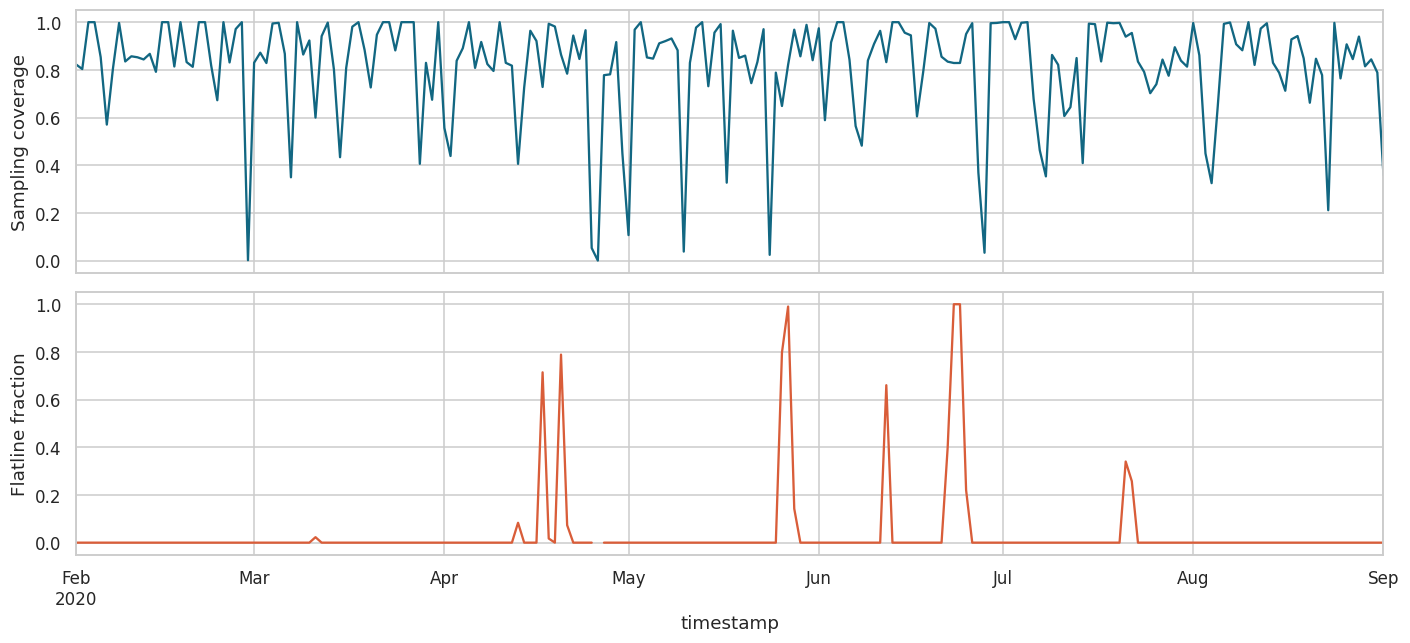

In [3]:
flat=pd.read_csv(OUT/'simultaneous_flatline_episodes.csv',parse_dates=['start','end'])
flat['flagged_duration_hours']=(flat.end-flat.start).dt.total_seconds()/3600
display(flat)
fig,axs=plt.subplots(2,1,figsize=(13,6),sharex=True)
x.availability.resample('1D').mean().plot(ax=axs[0],color='#126782'); axs[0].set_ylabel('Sampling coverage')
x.all_analog_flatline_fraction.resample('1D').mean().plot(ax=axs[1],color='#d95d39'); axs[1].set_ylabel('Flatline fraction'); plt.tight_layout(); plt.show()


In [4]:
audit=pd.DataFrame({'insufficient_coverage':x.availability.lt(.8),'incomplete_readings':x.complete_sensor_fraction.lt(.95),'simultaneous_flatlines':x.all_analog_flatline_fraction.gt(.2),'eligible':x.quality_eligible})
display(audit.groupby(x.split).sum())
# Quality reasons can overlap; do not sum reason counts as unique affected bins.
assert (x.loc[x.sample_count.eq(0),'quality_eligible']==False).all()
assert not x.loc[x.all_analog_flatline_fraction.gt(.2),'quality_eligible'].any()


,insufficient_coverage,incomplete_readings,simultaneous_flatlines,eligible
split,,,,
test,8480,0,2027,33614
train,1272,0,0,7079
validation,1339,0,4,7586


## Assess one long episode
Plotting every analog sensor in a common interval distinguishes a single quiet sensor from repeated complete snapshots. A flatline flag is a review item; without device logs its origin is unknown.

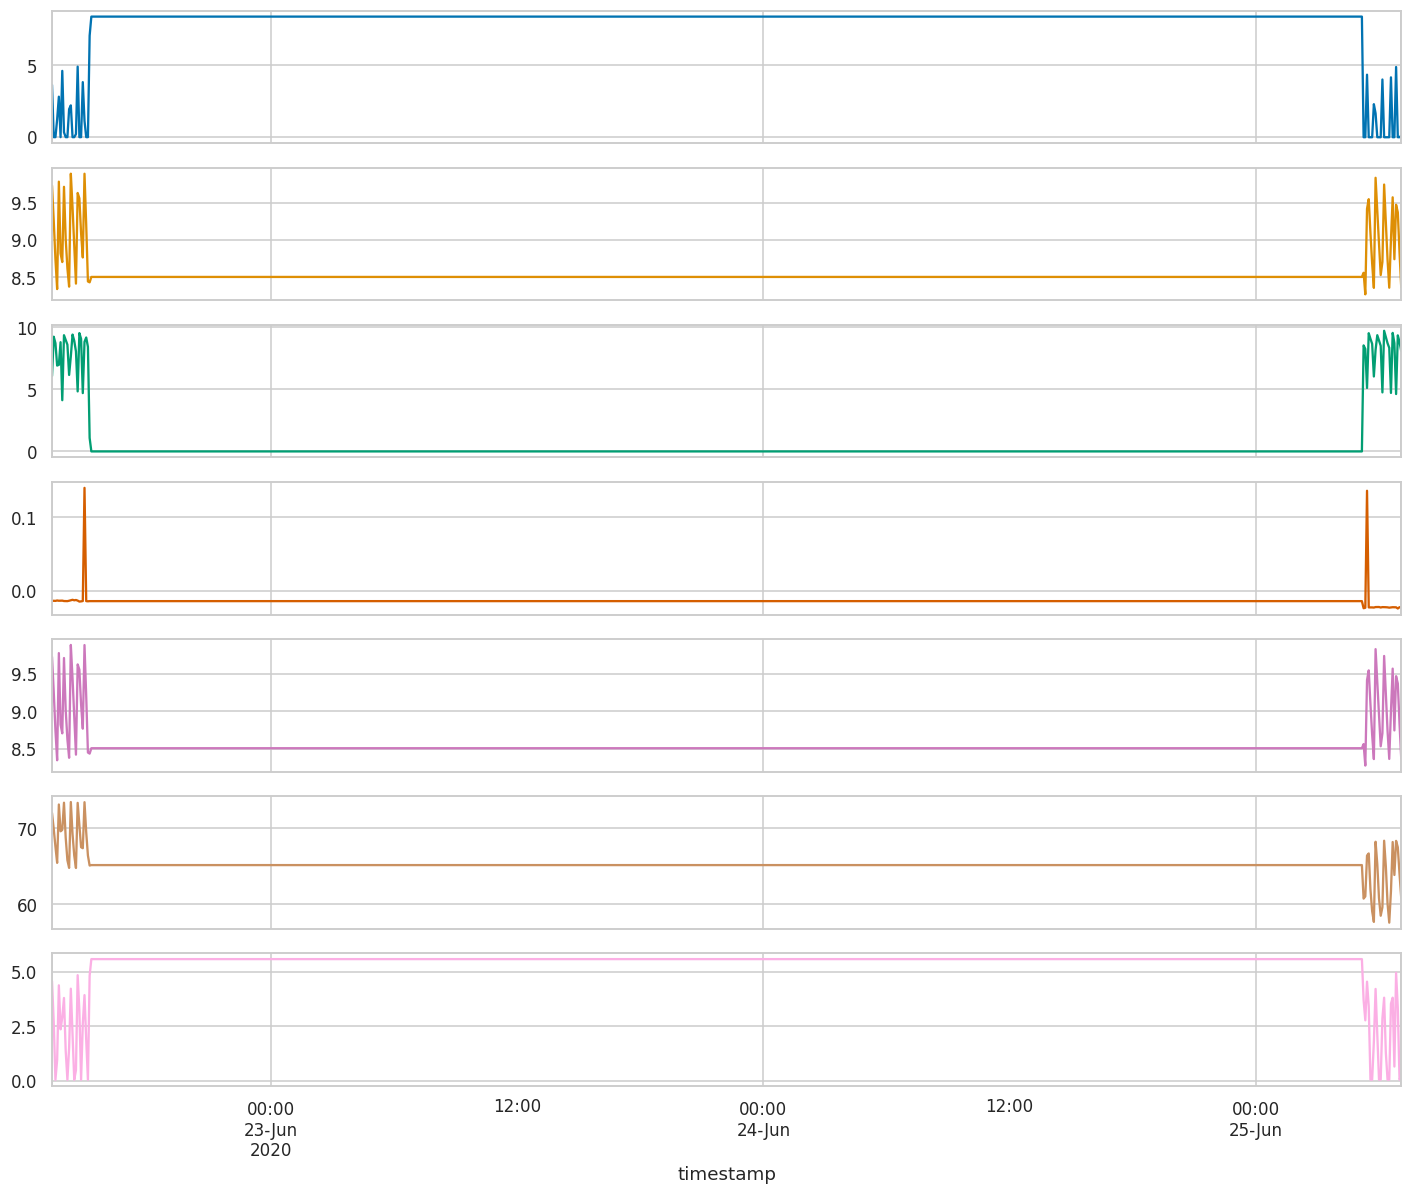

In [5]:
if len(flat):
    episode=flat.loc[flat.flagged_duration_hours.idxmax()]
    subset=x.loc[episode.start-pd.Timedelta('2h'):episode.end+pd.Timedelta('2h'),ANALOG]
    subset.plot(subplots=True,figsize=(13,11),legend=False); plt.tight_layout(); plt.show()


## Decisions
Preserve the raw file. Inspect telemetry transport and logger replay behaviour around long simultaneous flatlines. Do not call timestamp gaps hardware outages. Retain single-sensor flatlines for engineering review because quiet operating states and digital persistence can be legitimate.